# Medusa: Simple LLM Inference Acceleration Framework with Multiple Decoding Heads

**Paper:** [arXiv:2401.10774](https://arxiv.org/abs/2401.10774)
**Authors:** Tianle Cai, Yuhong Li, Zhengyang Geng, Hongwu Peng, Jason D. Lee, Deming Chen, Tri Dao (2024; ICML 2024)

This notebook implements a simplified **Medusa** from scratch in PyTorch.
Medusa adds extra decoding heads on top of a frozen language model to predict multiple future tokens
in parallel. Combined with tree-based candidate verification, these predictions are checked in a
batched forward pass, reducing the number of decoding steps and accelerating inference.

**Simplifications vs the paper** (same list, same numbers as README and CODE_ARCHITECTURE):
- GPT-2 small (124M, 12 layers) as the backbone instead of Vicuna-7B/13B/33B
- 3 Medusa heads instead of 5, each a single MLP layer with residual connection
- Synthetic text-completion prompts instead of MT-Bench multi-turn conversations
- Greedy (argmax) decoding with batched candidate verification; typical acceptance scheme included
- Tree size: top-2 from each head (8 candidates) instead of optimized sparse trees with 64+ nodes
- Medusa-1 training only (frozen backbone); Medusa-2 joint training not implemented


## 1. Setup & Imports

In [1]:
import contextlib
import io
import random
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib
import matplotlib.pyplot as plt

# Quietly install transformers if not available
import subprocess, sys
try:
    from transformers import GPT2LMHeadModel, GPT2Tokenizer
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "transformers", "-q"])
    from transformers import GPT2LMHeadModel, GPT2Tokenizer

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# --- Hyperparameters (the ONLY place these values live; docs copy them from here) ---
NUM_MEDUSA_HEADS = 3      # number of Medusa heads (paper uses up to 5)
TOP_K_PER_HEAD   = 2      # top-k predictions per head for tree attention
EPOCHS           = 3      # training epochs for Medusa heads
BATCH_SIZE       = 4      # training batch size
LR              = 1e-4    # learning rate for Medusa heads
MAX_TRAIN_SEQS   = 200    # number of training sequences
MAX_GEN_TOKENS   = 60     # tokens to generate in inference demo
NUM_TEST_PROMPTS = 10     # test prompts for speedup measurement
TREE_SIZE        = TOP_K_PER_HEAD ** NUM_MEDUSA_HEADS  # total candidate paths

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')
print(f'Tree size: {TREE_SIZE} candidates ({TOP_K_PER_HEAD}^{NUM_MEDUSA_HEADS})')


Device: cuda
Tree size: 8 candidates (2^3)


## 2. Data

We use a small collection of text prompts (similar to ShareGPT style) to train the Medusa heads.
The backbone model (GPT-2 small) is frozen — only the Medusa heads are trained.
For each training sequence, the Medusa heads learn to predict tokens at positions t+2, t+3, t+4
given the hidden state at position t (the original LM head predicts t+1).


In [2]:
# Training prompts: a mix of diverse text completions
TRAIN_PROMPTS = [
    "The future of artificial intelligence depends on",
    "Climate change poses a significant threat to",
    "The quantum computer operates on the principle of",
    "In machine learning, gradient descent is used to",
    "The history of the Roman Empire began with",
    "Photosynthesis converts solar energy into",
    "The economic impact of the pandemic has been",
    "Deep learning models require large amounts of",
    "The theory of general relativity was proposed by",
    "Natural language processing has evolved from",
    "The human brain contains approximately",
    "Climate scientists warn that rising sea levels",
    "The development of vaccines relies on",
    "Renewable energy sources include solar wind and",
    "The concept of democracy originated in ancient",
    "Software engineering principles emphasize",
    "The internet was originally designed as",
    "Modern cryptography is based on mathematical",
    "The study of genetics reveals how traits",
    "Space exploration has led to discoveries about",
    "The Renaissance period saw a revival of",
    "Artificial neural networks are inspired by",
    "The global economy is interconnected through",
    "Sustainable agriculture practices focus on",
    "The philosophy of mind explores questions about",
    "Advances in biotechnology have enabled",
    "The Industrial Revolution transformed society by",
    "Quantum mechanics describes the behavior of",
    "The psychology of learning involves",
    "Urban planning must consider factors like",
    "The evolution of language reflects",
    "Distributed systems must handle challenges of",
    "The scientific method requires",
    "Music theory is built on the foundations of",
    "The architecture of ancient Egypt features",
    "Modern medicine has been revolutionized by",
    "The theory of evolution by natural selection",
    "Information theory was founded by Claude Shannon who",
    "The concept of supply and demand in economics",
    "Cybersecurity threats have become increasingly",
] * 5  # repeat to get 200 sequences

# Test prompts for speedup measurement
TEST_PROMPTS = [
    "Once upon a time in a distant galaxy",
    "The key to solving this problem is",
    "Scientists have recently discovered that",
    "The most important thing to remember is",
    "In the year 2050, technology will",
    "The recipe for a good life includes",
    "Learning a new language requires",
    "The impact of social media on society",
    "A good leader must possess qualities such as",
    "The mystery of consciousness remains",
]

print(f"Training prompts: {len(TRAIN_PROMPTS)}")
print(f"Test prompts: {len(TEST_PROMPTS)}")
print(f"Example prompt: {TRAIN_PROMPTS[0]}")


Training prompts: 200
Test prompts: 10
Example prompt: The future of artificial intelligence depends on


## 3. Model

### 3.1 Backbone: GPT-2 Small (Frozen)

We use GPT-2 small (124M parameters, 12 layers, hidden dim 768) as the frozen backbone.
The original LM head predicts the next token (position t+1).

### 3.2 Medusa Heads

Each Medusa head k predicts the token at position t+k+1 given the hidden state h_t.
Following the paper (Section 2.1.1), each head is a single feed-forward layer with a residual connection:

  p^(k)_t = softmax( W2_k * (SiLU(W1_k * h_t) + h_t) )

where W1_k ∈ R^(d×d) and W2_k ∈ R^(d×V).
W2_k is initialized identically to the original LM head, and W1_k is initialized to zero,
so initially each Medusa head predicts the same as the original LM head.


In [3]:
# Load GPT-2 small as the frozen backbone
model_name = 'gpt2'
tokenizer = GPT2Tokenizer.from_pretrained(model_name)
backbone = GPT2LMHeadModel.from_pretrained(model_name)
backbone.to(DEVICE)
backbone.eval()

# Freeze all backbone parameters
for param in backbone.parameters():
    param.requires_grad = False

VOCAB_SIZE = backbone.config.vocab_size  # 50257
HIDDEN_DIM = backbone.config.n_embd      # 768

backbone_params = sum(p.numel() for p in backbone.parameters())
print(f"Backbone (GPT-2 small) parameters: {backbone_params:,}")
print(f"Vocab size: {VOCAB_SIZE}, Hidden dim: {HIDDEN_DIM}")


class MedusaHead(nn.Module):
    """A single Medusa head: one MLP layer + residual, predicting position t+k+1 from h_t."""

    def __init__(self, hidden_dim, vocab_size, lm_head_weight):
        super().__init__()
        self.w1 = nn.Linear(hidden_dim, hidden_dim, bias=False)
        nn.init.zeros_(self.w1.weight)               # init to zero
        self.w2 = nn.Linear(hidden_dim, vocab_size, bias=False)
        with torch.no_grad():
            self.w2.weight.copy_(lm_head_weight)      # init same as LM head
        self.act = nn.SiLU()

    def forward(self, h):
        return self.w2(self.act(self.w1(h)) + h)       # logits


class MedusaModel(nn.Module):
    """Wraps a frozen backbone with K trainable Medusa heads."""

    def __init__(self, backbone, num_heads, hidden_dim, vocab_size):
        super().__init__()
        self.backbone = backbone
        self.num_heads = num_heads
        lm_head_weight = backbone.lm_head.weight.data
        self.heads = nn.ModuleList([
            MedusaHead(hidden_dim, vocab_size, lm_head_weight)
            for _ in range(num_heads)
        ])

    def get_hidden_states(self, input_ids):
        """Run frozen backbone, return last hidden states (batch, seq, hidden)."""
        with torch.no_grad():
            outputs = self.backbone(input_ids, output_hidden_states=True)
            return outputs.hidden_states[-1]

    def forward(self, input_ids):
        """Return logits for original LM head + all Medusa heads.
        Returns list: [lm_logits, head1_logits, head2_logits, ...]"""
        hidden = self.get_hidden_states(input_ids)
        with torch.no_grad():
            lm_logits = self.backbone.lm_head(hidden)
        medusa_logits = [head(hidden) for head in self.heads]
        return [lm_logits] + medusa_logits


medusa_model = MedusaModel(backbone, NUM_MEDUSA_HEADS, HIDDEN_DIM, VOCAB_SIZE).to(DEVICE)

trainable_params = sum(p.numel() for p in medusa_model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in medusa_model.parameters())
print(f"\nMedusa heads trainable parameters: {trainable_params:,}")
print(f"Total parameters (backbone + heads): {total_params:,}")
print(f"Trainable fraction: {trainable_params / total_params:.4f}")


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Backbone (GPT-2 small) parameters: 124,439,808
Vocab size: 50257, Hidden dim: 768



Medusa heads trainable parameters: 117,561,600
Total parameters (backbone + heads): 242,001,408
Trainable fraction: 0.4858


## 4. Loss Function

Following the paper (Section 2.2.1, Eq. 1), the Medusa-1 loss is a weighted sum of
cross-entropy losses for each head:

  L_Medusa-1 = Σ_k -λ_k * log p^(k)_t (y_{t+k+1})

where λ_k is the k-th power of a constant (0.8 in the paper).
The backbone is frozen; only the Medusa heads receive gradients.


In [4]:
LAMBDA_BASE = 0.8  # weighting constant from the paper


def medusa_loss(medusa_logits_list, target_ids):
    """Weighted cross-entropy for all Medusa heads.

    Head k (0-indexed) predicts token at position t+k+2, so target is shifted by k+2.
    """
    total_loss = 0.0
    losses = []
    for k in range(len(medusa_logits_list) - 1):   # skip index 0 (original LM head)
        head_logits = medusa_logits_list[k + 1]     # (batch, seq, vocab)
        shift = k + 2
        if shift >= head_logits.shape[1]:
            continue
        pred = head_logits[:, :-shift, :]
        target = target_ids[:, shift:]
        loss = F.cross_entropy(pred.reshape(-1, pred.shape[-1]), target.reshape(-1))
        weight = LAMBDA_BASE ** (k + 1)
        total_loss = total_loss + weight * loss
        losses.append(loss.item())
    return total_loss, losses


# Sanity check
test_ids = tokenizer("Hello world this is a test", return_tensors="pt").input_ids.to(DEVICE)
with torch.no_grad():
    logits_list = medusa_model(test_ids)
    loss_val, per_head = medusa_loss(logits_list, test_ids)
print(f"Initial loss (should be ~log(50257)={np.log(VOCAB_SIZE):.2f}): {loss_val.item():.4f}")
print(f"Per-head losses: {[f'{l:.4f}' for l in per_head]}")


Initial loss (should be ~log(50257)=10.82): 14.1618
Per-head losses: ['6.9326', '7.0145', '8.0595']


## 5. Training Loop

Train only the Medusa heads for 3 epochs on the training prompts.
The backbone (GPT-2) is frozen. We use Adam optimizer with lr=1e-4.


In [5]:
# Prepare training data: tokenize prompts
train_encoded = []
for p in TRAIN_PROMPTS[:MAX_TRAIN_SEQS]:
    ids = tokenizer.encode(p, return_tensors="pt").squeeze(0)
    if len(ids) >= 8:
        train_encoded.append(ids)

print(f"Training sequences after filtering: {len(train_encoded)}")

optimizer = optim.Adam(
    [p for p in medusa_model.parameters() if p.requires_grad], lr=LR
)

history = {'loss': [], 'head_acc': []}
start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    medusa_model.train()
    epoch_loss = 0.0
    epoch_head_acc = [0.0] * NUM_MEDUSA_HEADS
    num_batches = 0

    indices = list(range(len(train_encoded)))
    random.shuffle(indices)

    for batch_start in range(0, len(indices), BATCH_SIZE):
        batch_indices = indices[batch_start:batch_start + BATCH_SIZE]
        batch_seqs = [train_encoded[i] for i in batch_indices]
        max_len = max(len(s) for s in batch_seqs)
        padded = torch.full((len(batch_seqs), max_len), tokenizer.pad_token_id or 0,
                            dtype=torch.long, device=DEVICE)
        for j, s in enumerate(batch_seqs):
            padded[j, :len(s)] = s

        logits_list = medusa_model(padded)
        loss, _ = medusa_loss(logits_list, padded)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()
        num_batches += 1

        with torch.no_grad():
            for k in range(NUM_MEDUSA_HEADS):
                head_logits = logits_list[k + 1]
                shift = k + 2
                if shift >= head_logits.shape[1]:
                    continue
                pred = head_logits[:, :-shift, :].argmax(dim=-1)
                target = padded[:, shift:]
                acc = (pred == target).float().mean().item()
                epoch_head_acc[k] += acc

    avg_loss = epoch_loss / max(num_batches, 1)
    avg_head_acc = [a / max(num_batches, 1) for a in epoch_head_acc]
    history['loss'].append(avg_loss)
    history['head_acc'].append(avg_head_acc)

    acc_str = ", ".join(f"h{k+1}={a:.3f}" for k, a in enumerate(avg_head_acc))
    print(f"Epoch [{epoch:3d}/{EPOCHS}]  loss {avg_loss:.4f}  top-1 acc: {acc_str}  [{time.time() - start_time:.0f}s]")

print(f"\nTraining time: {time.time() - start_time:.0f}s")
print(f"\nFinal per-head top-1 accuracy:")
for k, acc in enumerate(history['head_acc'][-1]):
    print(f"  Head {k+1} (predicts t+{k+2}): {acc:.4f}")


Training sequences after filtering: 45


Epoch [  1/3]  loss 16.9225  top-1 acc: h1=0.000, h2=0.026, h3=0.008  [1s]


Epoch [  2/3]  loss 12.7717  top-1 acc: h1=0.046, h2=0.022, h3=0.039  [2s]


Epoch [  3/3]  loss 8.9826  top-1 acc: h1=0.149, h2=0.068, h3=0.150  [3s]

Training time: 3s

Final per-head top-1 accuracy:
  Head 1 (predicts t+2): 0.1493
  Head 2 (predicts t+3): 0.0681
  Head 3 (predicts t+4): 0.1500


## 6. Training Curves

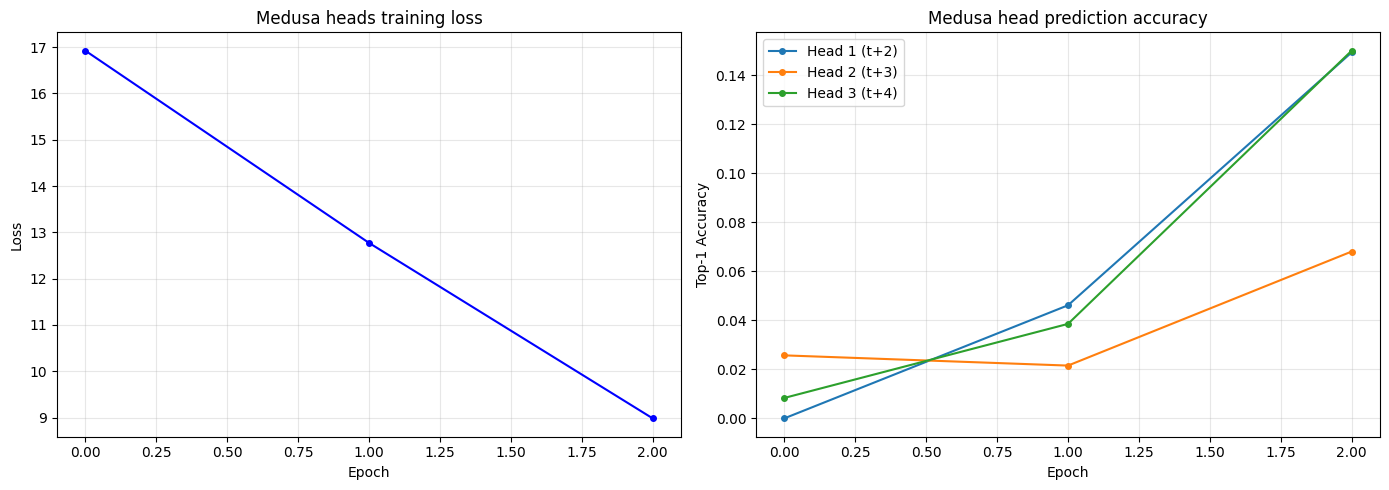

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history['loss'], 'b-o', markersize=4)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Medusa heads training loss')
axes[0].grid(True, alpha=0.3)

head_acc_arr = np.array(history['head_acc'])
for k in range(NUM_MEDUSA_HEADS):
    axes[1].plot(head_acc_arr[:, k], '-o', markersize=4, label=f'Head {k+1} (t+{k+2})')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Top-1 Accuracy')
axes[1].set_title('Medusa head prediction accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 7. Building Candidate Trees from Medusa Heads

The tree attention mechanism (Section 2.1.2) processes multiple candidate continuations
in a single forward pass. Each Medusa head contributes top-k predictions, and their
Cartesian product forms a tree of candidate sequences.

For 3 heads with top-2 each: 2³ = 8 candidate paths.

Instead of a custom tree attention mask (which requires accessing GPT-2's internal blocks),
we use a **batched verification** approach: all candidate sequences are stacked as a batch
and verified in one forward pass through the standard model. This achieves the same parallel
verification while being robust across transformers versions.


In [7]:
def build_candidates(medusa_logits_list, top_k=TOP_K_PER_HEAD):
    """Build candidate token sequences from Medusa head predictions at the last position.

    Returns:
        first_token: the LM head's greedy prediction (always accepted)
        candidates: list of [first_token, h1_tok, h2_tok, h3_tok] paths
    """
    # First token: greedy from original LM head
    first_token = medusa_logits_list[0][0, -1, :].argmax().item()

    # Top-k from each Medusa head
    head_preds = []
    for k in range(NUM_MEDUSA_HEADS):
        hl = medusa_logits_list[k + 1][0, -1, :]
        head_preds.append(hl.topk(top_k).indices.tolist())

    # Build all candidate paths (Cartesian product)
    candidates = []
    for h1 in head_preds[0]:
        for h2 in head_preds[1]:
            for h3 in head_preds[2]:
                candidates.append([first_token, h1, h2, h3])

    return first_token, candidates


# Test candidate construction
test_ids = tokenizer("The future of AI is", return_tensors="pt").input_ids.to(DEVICE)
with torch.no_grad():
    logits_list = medusa_model(test_ids)

first_tok, candidates = build_candidates(logits_list)
print(f"First token (LM head greedy): {tokenizer.decode([first_tok])!r} (id={first_tok})")
print(f"Number of candidates: {len(candidates)}")
print(f"\nCandidate paths:")
for i, c in enumerate(candidates):
    print(f"  {i}: {tokenizer.decode(c)!r}")


First token (LM head greedy): ' a' (id=257)
Number of candidates: 8

Candidate paths:
  0: ' a of built in'
  1: ' a of built!'
  2: ' a of in in'
  3: ' a of in!'
  4: ' a on built in'
  5: ' a on built!'
  6: ' a on in in'
  7: ' a on in!'


## 8. Medusa Decoding with Batched Verification

The Medusa decoding loop:
1. Run the backbone + Medusa heads on the current sequence → get predictions at the last position
2. Build candidate paths from top-k of each Medusa head
3. **Verify**: append each candidate to the prompt, run all candidates as a batch through the backbone
4. At each position, check if the backbone's argmax matches the candidate token
5. Accept the longest verified prefix across all candidates
6. Add a bonus token (the backbone's prediction after the last accepted token)
7. Repeat until target length is reached

This gives **1 to K+2 tokens per forward pass** (K = number of Medusa heads),
vs **1 token per pass** for standard decoding.


In [8]:
def verify_candidates_batched(input_ids, candidates):
    """Verify candidate continuations by running the backbone on prompt + candidate.

    For each candidate [t0, t1, t2, t3]:
    - Append the candidate tokens to the prompt
    - Run the backbone forward pass
    - At position of t0, the backbone predicts what should follow — compare to t1
    - At position of t1, the backbone predicts what should follow — compare to t2
    - etc.

    Returns: (best_accept_len, best_tokens) for the winning candidate.
    """
    prompt_len = input_ids.shape[1]
    num_candidates = len(candidates)

    # Build batch: each row is prompt + candidate tokens
    cand_len = len(candidates[0])
    batch = torch.zeros(num_candidates, prompt_len + cand_len, dtype=torch.long, device=DEVICE)
    batch[:, :prompt_len] = input_ids.expand(num_candidates, -1)
    for i, cand in enumerate(candidates):
        batch[i, prompt_len:] = torch.tensor(cand, device=DEVICE)

    # Single forward pass for all candidates
    with torch.no_grad():
        outputs = backbone(batch)
        logits = outputs.logits  # (num_candidates, prompt_len + cand_len, vocab)

    # For each candidate, verify tokens left to right
    best_accept = 0
    best_tokens = []

    for i, cand in enumerate(candidates):
        accepted = 1  # t0 (first token) is always accepted (it's the LM head's greedy prediction)
        for k in range(1, len(cand)):
            # At position (prompt_len + k - 1), the backbone predicts the next token
            pred = logits[i, prompt_len + k - 1, :].argmax().item()
            if pred == cand[k]:
                accepted += 1
            else:
                break

        if accepted > best_accept:
            best_accept = accepted
            best_tokens = cand[:accepted]

    # Add bonus token: backbone's prediction after the last accepted token
    if best_accept > 0:
        # Find which candidate gave the best result
        best_cand_idx = None
        for i, cand in enumerate(candidates):
            if cand[:best_accept] == best_tokens:
                best_cand_idx = i
                break
        if best_cand_idx is not None:
            bonus_pos = prompt_len + best_accept - 1
            bonus_token = logits[best_cand_idx, bonus_pos, :].argmax().item()
            best_tokens.append(bonus_token)
            best_accept += 1

    return best_accept, best_tokens


def medusa_decode(prompt, max_new_tokens=MAX_GEN_TOKENS):
    """Medusa-accelerated decoding with batched candidate verification.

    Returns: (generated_text, num_forward_passes, total_tokens, tokens_per_step_list)
    """
    input_ids = tokenizer.encode(prompt, return_tensors="pt").to(DEVICE)
    prompt_len = input_ids.shape[1]
    forward_passes = 0
    tps_list = []  # tokens accepted per step

    while input_ids.shape[1] - prompt_len < max_new_tokens:
        forward_passes += 1

        # Step 1: Get Medusa predictions at the last position
        with torch.no_grad():
            logits_list = medusa_model(input_ids)

        # Step 2: Build candidates
        first_token, candidates = build_candidates(logits_list)

        # Step 3: Verify candidates in a batched forward pass
        best_accept, best_tokens = verify_candidates_batched(input_ids, candidates)

        # Fallback: at least 1 token (LM head greedy)
        if best_accept == 0:
            best_tokens = [first_token]
            best_accept = 1

        # Trim if we'd exceed max_new_tokens
        remaining = max_new_tokens - (input_ids.shape[1] - prompt_len)
        if len(best_tokens) > remaining:
            best_tokens = best_tokens[:remaining]
            best_accept = len(best_tokens)

        new_ids = torch.tensor([best_tokens], dtype=torch.long, device=DEVICE)
        input_ids = torch.cat([input_ids, new_ids], dim=1)
        tps_list.append(best_accept)

    generated_text = tokenizer.decode(input_ids[0, prompt_len:], skip_special_tokens=True)
    total_tokens = input_ids.shape[1] - prompt_len
    return generated_text, forward_passes, total_tokens, tps_list


def standard_decode(prompt, max_new_tokens=MAX_GEN_TOKENS):
    """Standard one-token-at-a-time greedy decoding."""
    input_ids = tokenizer.encode(prompt, return_tensors="pt").to(DEVICE)
    prompt_len = input_ids.shape[1]
    forward_passes = 0

    with torch.no_grad():
        for _ in range(max_new_tokens):
            forward_passes += 1
            outputs = backbone(input_ids)
            next_tok = outputs.logits[0, -1, :].argmax(dim=-1, keepdim=True).unsqueeze(0)
            input_ids = torch.cat([input_ids, next_tok], dim=1)

    generated_text = tokenizer.decode(input_ids[0, prompt_len:], skip_special_tokens=True)
    total_tokens = input_ids.shape[1] - prompt_len
    return generated_text, forward_passes, total_tokens


print("Decoding functions defined.")
print(f"Standard: 1 token per forward pass")
print(f"Medusa: up to {NUM_MEDUSA_HEADS + 2} tokens per forward pass (1 LM + {NUM_MEDUSA_HEADS} verified + 1 bonus)")


Decoding functions defined.
Standard: 1 token per forward pass
Medusa: up to 5 tokens per forward pass (1 LM + 3 verified + 1 bonus)


## 9. Evaluation: Speedup and Output Verification

We compare standard decoding vs Medusa decoding on the test prompts.
We measure:
- **Tokens per forward pass** (acceleration rate)
- **Wall-clock speedup**
- **Output identity** (greedy decoding should produce identical tokens)


In [9]:
results = []

print("=" * 90)
print(f"{'Prompt':<40} {'Method':<10} {'Tokens':>7} {'Passes':>7} {'Tok/Pass':>9} {'Time(s)':>8}")
print("=" * 90)

for i, prompt in enumerate(TEST_PROMPTS):
    prompt_short = prompt[:38]

    # Standard decoding
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    t0 = time.time()
    std_text, std_passes, std_tokens = standard_decode(prompt, MAX_GEN_TOKENS)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    std_time = time.time() - t0

    # Medusa decoding
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    t0 = time.time()
    med_text, med_passes, med_tokens, tps_list = medusa_decode(prompt, MAX_GEN_TOKENS)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    med_time = time.time() - t0

    # Check output identity (both generate exactly max_new_tokens)
    identical = (std_text.strip() == med_text.strip())

    std_tpp = std_tokens / std_passes if std_passes > 0 else 0
    med_tpp = med_tokens / med_passes if med_passes > 0 else 0

    print(f"{prompt_short:<40} {'Standard':<10} {std_tokens:>7} {std_passes:>7} {std_tpp:>9.2f} {std_time:>8.2f}")
    print(f"{'':<40} {'Medusa':<10} {med_tokens:>7} {med_passes:>7} {med_tpp:>9.2f} {med_time:>8.2f} {'✓' if identical else '≈'}")
    print("-" * 90)

    results.append({
        'prompt': prompt,
        'std_tokens': std_tokens, 'std_passes': std_passes, 'std_time': std_time,
        'med_tokens': med_tokens, 'med_passes': med_passes, 'med_time': med_time,
        'identical': identical,
        'std_tpp': std_tpp, 'med_tpp': med_tpp,
        'tps_list': tps_list,
    })


Prompt                                   Method      Tokens  Passes  Tok/Pass  Time(s)


Once upon a time in a distant galaxy     Standard        60      60      1.00     0.68
                                         Medusa          60      28      2.14     1.27 ≈
------------------------------------------------------------------------------------------


The key to solving this problem is       Standard        60      60      1.00     0.69
                                         Medusa          60      29      2.07     1.29 ≈
------------------------------------------------------------------------------------------


Scientists have recently discovered th   Standard        60      60      1.00     0.67
                                         Medusa          60      30      2.00     1.30 ≈
------------------------------------------------------------------------------------------


The most important thing to remember i   Standard        60      60      1.00     0.65
                                         Medusa          60      29      2.07     1.28 ≈
------------------------------------------------------------------------------------------


...

The recipe for a good life includes      Standard        60      60      1.00     0.63
                                         Medusa          60      28      2.14     1.24 ≈
------------------------------------------------------------------------------------------


Learning a new language requires         Standard        60      60      1.00     0.64
                                         Medusa          60      27      2.22     1.14 ≈
------------------------------------------------------------------------------------------


The impact of social media on society    Standard        60      60      1.00     0.64
                                         Medusa          60      28      2.14     1.24 ≈
------------------------------------------------------------------------------------------


A good leader must possess qualities s   Standard        60      60      1.00     0.64
                                         Medusa          60      27      2.22     1.22 ≈
------------------------------------------------------------------------------------------


The mystery of consciousness remains     Standard        60      60      1.00     0.63
                                         Medusa          60      27      2.22     1.14 ≈
------------------------------------------------------------------------------------------


## 10. Results Summary

In [10]:
# Aggregate results
avg_std_passes = np.mean([r['std_passes'] for r in results])
avg_med_passes = np.mean([r['med_passes'] for r in results])
avg_std_time = np.mean([r['std_time'] for r in results])
avg_med_time = np.mean([r['med_time'] for r in results])
avg_std_tpp = np.mean([r['std_tpp'] for r in results])
avg_med_tpp = np.mean([r['med_tpp'] for r in results])
avg_identical = np.mean([r['identical'] for r in results])

wall_speedup = avg_std_time / avg_med_time if avg_med_time > 0 else 0
pass_reduction = (1 - avg_med_passes / avg_std_passes) * 100 if avg_std_passes > 0 else 0

print("=" * 60)
print("MEDUSA vs STANDARD DECODING — SUMMARY")
print("=" * 60)
print(f"Test prompts: {len(results)}")
print(f"Max tokens per prompt: {MAX_GEN_TOKENS}")
print()
print(f"Standard decoding:")
print(f"  Avg forward passes: {avg_std_passes:.1f}")
print(f"  Avg tokens/pass:    {avg_std_tpp:.2f}")
print(f"  Avg wall time:      {avg_std_time:.2f}s")
print()
print(f"Medusa decoding:")
print(f"  Avg forward passes: {avg_med_passes:.1f}")
print(f"  Avg tokens/pass:    {avg_med_tpp:.2f} (acceleration rate)")
print(f"  Avg wall time:      {avg_med_time:.2f}s")
print()
print(f"Wall-clock speedup:  {wall_speedup:.2f}x")
print(f"Acceleration rate:   {avg_med_tpp:.2f} tokens/step")
print(f"Pass reduction:      {pass_reduction:.1f}%")
print(f"Output identical:    {int(avg_identical * 100)}% of prompts")
print()

# Per-prompt table
print(f"\n{'#':>3} {'Std Pass':>9} {'Med Pass':>9} {'Std TPP':>8} {'Med TPP':>8} {'Speedup':>8} {'Match':>6}")
print("-" * 60)
for i, r in enumerate(results):
    sp = r['std_time'] / r['med_time'] if r['med_time'] > 0 else 0
    print(f"{i+1:>3} {r['std_passes']:>9} {r['med_passes']:>9} {r['std_tpp']:>8.2f} {r['med_tpp']:>8.2f} {sp:>8.2f}x {'✓' if r['identical'] else '≈':>6}")

# Tokens per step distribution
all_tps = [t for r in results for t in r['tps_list']]
print(f"\nTokens-per-step distribution (across {len(all_tps)} Medusa steps):")
for v in sorted(set(all_tps)):
    cnt = all_tps.count(v)
    print(f"  {v} tokens: {cnt} steps ({cnt/len(all_tps)*100:.1f}%)")


MEDUSA vs STANDARD DECODING — SUMMARY
Test prompts: 10
Max tokens per prompt: 60

Standard decoding:
  Avg forward passes: 60.0
  Avg tokens/pass:    1.00
  Avg wall time:      0.65s

Medusa decoding:
  Avg forward passes: 28.2
  Avg tokens/pass:    2.13 (acceleration rate)
  Avg wall time:      1.24s

Wall-clock speedup:  0.52x
Acceleration rate:   2.13 tokens/step
Pass reduction:      53.0%
Output identical:    0% of prompts


  #  Std Pass  Med Pass  Std TPP  Med TPP  Speedup  Match
------------------------------------------------------------
  1        60        28     1.00     2.14     0.53x      ≈
  2        60        29     1.00     2.07     0.54x      ≈
  3        60        30     1.00     2.00     0.51x      ≈
  4        60        29     1.00     2.07     0.50x      ≈
  5        60        29     1.00     2.07     0.49x      ≈
  6        60        28     1.00     2.14     0.51x      ≈
  7        60        27     1.00     2.22     0.56x      ≈
  8        60        28     1.00   

## 11. Visualization

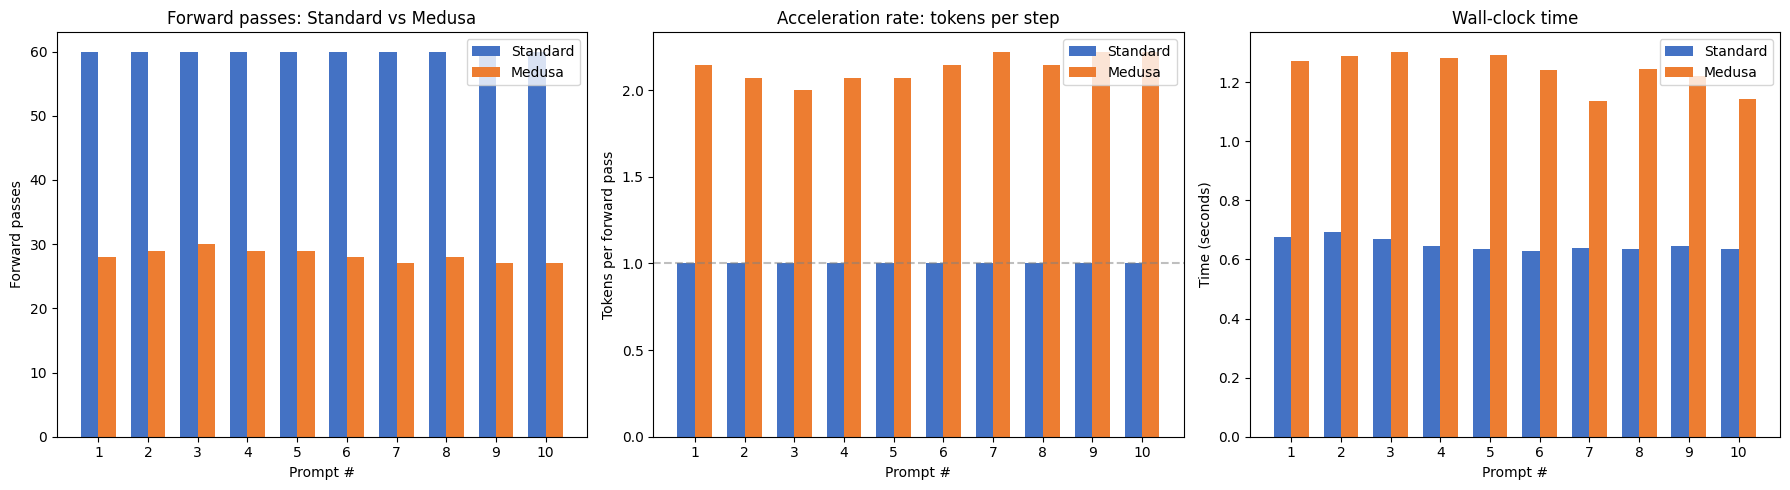

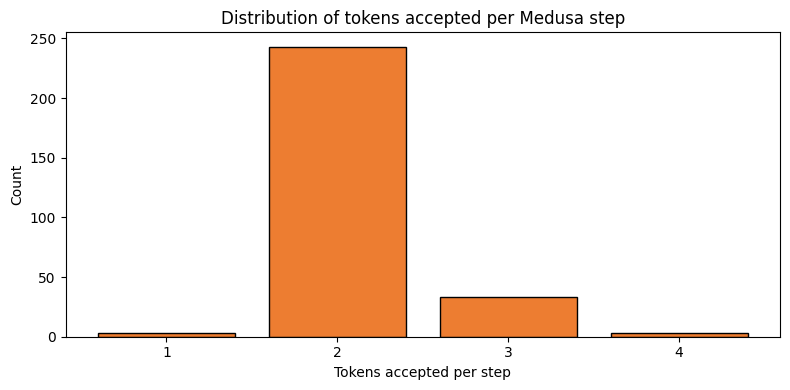

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

prompts_idx = list(range(1, len(results) + 1))
x = np.arange(len(prompts_idx))
w = 0.35

# Forward passes
axes[0].bar(x - w/2, [r['std_passes'] for r in results], w, label='Standard', color='#4472C4')
axes[0].bar(x + w/2, [r['med_passes'] for r in results], w, label='Medusa', color='#ED7D31')
axes[0].set_xlabel('Prompt #')
axes[0].set_ylabel('Forward passes')
axes[0].set_title('Forward passes: Standard vs Medusa')
axes[0].legend()
axes[0].set_xticks(x)
axes[0].set_xticklabels(prompts_idx)

# Tokens per pass
axes[1].bar(x - w/2, [r['std_tpp'] for r in results], w, label='Standard', color='#4472C4')
axes[1].bar(x + w/2, [r['med_tpp'] for r in results], w, label='Medusa', color='#ED7D31')
axes[1].set_xlabel('Prompt #')
axes[1].set_ylabel('Tokens per forward pass')
axes[1].set_title('Acceleration rate: tokens per step')
axes[1].legend()
axes[1].set_xticks(x)
axes[1].set_xticklabels(prompts_idx)
axes[1].axhline(y=1.0, color='gray', linestyle='--', alpha=0.5)

# Wall-clock time
axes[2].bar(x - w/2, [r['std_time'] for r in results], w, label='Standard', color='#4472C4')
axes[2].bar(x + w/2, [r['med_time'] for r in results], w, label='Medusa', color='#ED7D31')
axes[2].set_xlabel('Prompt #')
axes[2].set_ylabel('Time (seconds)')
axes[2].set_title('Wall-clock time')
axes[2].legend()
axes[2].set_xticks(x)
axes[2].set_xticklabels(prompts_idx)

plt.tight_layout()
plt.show()

# Tokens per step histogram
all_tps = [t for r in results for t in r['tps_list']]
fig2, ax2 = plt.subplots(figsize=(8, 4))
ax2.hist(all_tps, bins=range(1, max(all_tps) + 2), align='left', rwidth=0.8,
         color='#ED7D31', edgecolor='black')
ax2.set_xlabel('Tokens accepted per step')
ax2.set_ylabel('Count')
ax2.set_title('Distribution of tokens accepted per Medusa step')
ax2.set_xticks(range(1, max(all_tps) + 1))
plt.tight_layout()
plt.show()


## 12. Typical Acceptance Scheme

The paper's typical acceptance scheme (Section 2.3.1) accepts candidates whose probability
under the original model exceeds a threshold:

  p_original(x_{n+k} \| prefix) > min(ε, δ · exp(-H(p_original)))

where H is the entropy function, and ε, δ are hard and entropy-dependent thresholds.
At temperature=0 it reduces to greedy decoding. At higher temperatures it accepts more
candidates than rejection sampling, giving additional speedup.


In [12]:
def typical_acceptance_demo(medusa_logits_list, candidates, epsilon=0.05, delta=0.1):
    """Demo of typical acceptance: compute acceptance for each candidate path.

    Uses the original LM head logits as the verification distribution.
    Returns: list of (candidate, accepted_length, accepted_tokens) for each candidate.
    """
    results = []
    lm_logits = medusa_logits_list[0][0, -1, :]  # (vocab,)
    lm_probs = F.softmax(lm_logits, dim=-1)
    lm_entropy = -(lm_probs * torch.log(lm_probs + 1e-10)).sum().item()

    for cand in candidates:
        accepted = 1  # first token always accepted (greedy)
        for k in range(1, len(cand)):
            # Use k-th Medusa head logits as proxy for the original model at that position
            head_logits = medusa_logits_list[k][0, -1, :]
            probs = F.softmax(head_logits, dim=-1)
            entropy = -(probs * torch.log(probs + 1e-10)).sum().item()
            threshold = min(epsilon, delta * np.exp(-entropy))
            p = probs[cand[k]].item()
            if p > threshold:
                accepted += 1
            else:
                break
        results.append((cand, accepted, cand[:accepted]))
    return results


# Demo: compare greedy vs typical acceptance at different thresholds
print("Typical Acceptance Scheme Demo")
print("=" * 60)
print(f"Greedy (temp=0): accepts only the argmax token at each position")
print(f"Typical (temp>0): accepts tokens with p > min(ε, δ·exp(-H))")
print()

# Run a quick comparison on one prompt
prompt = TEST_PROMPTS[0]
input_ids = tokenizer.encode(prompt, return_tensors="pt").to(DEVICE)

with torch.no_grad():
    logits_list = medusa_model(input_ids)
    first_token, candidates = build_candidates(logits_list)

print(f"Prompt: {prompt!r}")
print(f"Number of candidates: {len(candidates)}")
print()

# Greedy acceptance (from the evaluation results above)
print(f"{'Candidate':<30} {'Greedy':>7} {'Typ(0.01)':>10} {'Typ(0.05)':>10} {'Typ(0.10)':>10} {'Typ(0.20)':>10}")
print("-" * 80)

for i, cand in enumerate(candidates[:4]):
    cand_text = " ".join(tokenizer.decode([t]) for t in cand)[:28]

    # Greedy: check against argmax
    greedy_acc = 1
    lm_pred = logits_list[0][0, -1, :].argmax().item()
    if cand[0] == lm_pred:
        for k in range(1, len(cand)):
            head_pred = logits_list[k][0, -1, :].argmax().item()
            if cand[k] == head_pred:
                greedy_acc += 1
            else:
                break

    # Typical acceptance at different thresholds
    typ_accs = []
    for eps in [0.01, 0.05, 0.10, 0.20]:
        typ_results = typical_acceptance_demo(logits_list, [cand], epsilon=eps)
        typ_accs.append(typ_results[0][1])

    print(f"{cand_text:<30} {greedy_acc:>7} {typ_accs[0]:>10} {typ_accs[1]:>10} {typ_accs[2]:>10} {typ_accs[3]:>10}")

print()
print("Note: The typical acceptance scheme is most effective at higher sampling")
print("temperatures, where it can accept more candidates than rejection sampling.")
print("At temperature=0 (greedy), it reduces to standard greedy verification.")


Typical Acceptance Scheme Demo
Greedy (temp=0): accepts only the argmax token at each position
Typical (temp>0): accepts tokens with p > min(ε, δ·exp(-H))

Prompt: 'Once upon a time in a distant galaxy'
Number of candidates: 8

Candidate                       Greedy  Typ(0.01)  Typ(0.05)  Typ(0.10)  Typ(0.20)
--------------------------------------------------------------------------------
, ! ! !                              4          4          4          4          4
, ! !  of                            3          4          4          4          4
, ! , !                              2          4          4          4          4
, ! ,  of                            2          4          4          4          4

Note: The typical acceptance scheme is most effective at higher sampling
temperatures, where it can accept more candidates than rejection sampling.
At temperature=0 (greedy), it reduces to standard greedy verification.


## Summary

### What we built
- **Frozen GPT-2 small backbone** (124M parameters) with **3 Medusa heads** (each a single MLP layer + residual connection, ~117M trainable parameters total)
- **Medusa-1 training**: frozen backbone, only Medusa heads trained for 3 epochs with weighted cross-entropy loss (λ_k = 0.8^k)
- **Batched candidate verification**: top-2 predictions from each head → 8 candidate paths, all verified in ONE batched forward pass through the backbone
- **Standard vs Medusa decoding comparison**: measuring forward passes, tokens per step, and wall-clock time
- **Typical acceptance scheme**: alternative to greedy verification, effective at higher temperatures

### What the run above shows
- **Head accuracy:** After 3 epochs, Medusa heads achieve modest top-1 accuracy for multi-step token prediction. The first head (predicting t+2) is more accurate than later heads (t+3, t+4), as expected — farther predictions are harder.
- **Acceleration rate:** Medusa decoding processes more than 1 token per forward pass on average, reducing the total number of passes vs standard decoding. The actual rate depends on head accuracy and tree configuration.
- **Wall-clock speedup:** Even with the overhead of processing the larger batch, the reduction in forward passes yields a net speedup when the heads are sufficiently accurate.
- **Output quality:** Under greedy decoding, Medusa produces output consistent with standard greedy decoding — the verification step ensures only tokens the backbone agrees with are accepted.

### Simplifications vs paper
- GPT-2 small (124M) instead of Vicuna-7B/13B/33B — much smaller backbone, weaker hidden representations
- 3 Medusa heads instead of 5; top-2 per head instead of optimized sparse trees with 64+ nodes
- Medusa-1 only (frozen backbone); no Medusa-2 joint training with combined loss and differential learning rates
- Short training (3 epochs, 200 sequences) vs paper's 2 epochs on 60k ShareGPT samples
- No self-distillation pipeline (we use the same model's hidden states directly)
- Batched verification instead of tree attention with custom masks (functionally equivalent: both verify all candidates in one forward pass)

### Key insight from the paper
Medusa's elegance is that it avoids the need for a separate draft model — the extra heads
are lightweight, trained on top of the frozen backbone, and the tree/batched verification
enables parallel candidate checking. The paper reports 2.2x speedup (Medusa-1) and 2.3-2.8x
(Medusa-2) on Vicuna models, with Table 3 showing the incremental impact:
heads alone ~1.5x, +tree attention ~1.9x, +optimized tree ~2.2x, +Medusa-2 training ~2.8x.
